In [9]:
import torch
import numpy as np
import cv2
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, CrossEntropyLoss, Module, Dropout, Flatten
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam
from pathlib import Path
import matplotlib.pyplot as plt

In [10]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray) -> None:
        self._x = torch.from_numpy(datas).float()
        self._y = torch.from_numpy(labels).long()

    def __len__(self) -> int:
        return len(self._x)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        int(idx)
        return self._x[idx], self._y[idx]

In [11]:
class CustomModel(Module):
    def __init__(self, input_size: int, output_size) -> None:
        super().__init__()
        self.net = Sequential(
            Flatten(),
            Linear(input_size, 128),
            ReLU(),
            Dropout(p=0.15),
            Linear(128,128),
            ReLU(),
            Dropout(p=0.15),
            Linear(128,64),
            ReLU(),
            Linear(64, output_size)
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.net(x)

In [12]:
def train_model_class(features, targets, kf, batch, epochs, criterion, exp=False):
    acc_scores = []
    f1_scores = []
    folds_loss = []
    folds_acc = []
    for i, (train_index, test_index) in enumerate(kf.split(features, targets)):
        print(f"Treinando modelo ----- Fold {i + 1}")
        train_data = MyDataset(features[train_index], targets[train_index])
        train_loader = DataLoader(train_data, batch_size=batch)
        model = CustomModel(16900, 2)
        optmizer = Adam(model.parameters(), lr=0.001)
        epoch_loss = []
        epoch_acc = []
        for i_epochs in range(epochs):    
            model.train()
            batches_loss = []
            batches_acc = []
            for x, y in train_loader:
                optmizer.zero_grad()
                output = model(x)
                loss = criterion(output, y)
                loss.backward()
                optmizer.step()
                batches_loss.append(loss.item())
                batches_acc.append(accuracy_score(y, torch.argmax(output, dim=1).cpu().numpy()))

            epoch_loss.append(np.mean(batches_loss))
            epoch_acc.append(np.mean(batches_acc))

        folds_loss.append(epoch_loss)
        folds_acc.append(epoch_acc)
        model.eval()
        with torch.no_grad():
            x_test_tensor = Tensor(features[test_index]).float()
            y_true = targets[test_index]
            output = model(x_test_tensor)
            result = torch.argmax(output, dim=1).cpu().numpy()
            acc_s = accuracy_score(y_true, result)
            f1_s = f1_score(y_true, result, average="macro")
            cm = confusion_matrix(y_true, result)
            acc_scores.append(acc_s)
            f1_scores.append(f1_s)
            print(f"Acc: {acc_s}")
            print(f"F1-Score: {f1_s}")
            print(f"CM: {cm}")

        if exp:
            break

    print(f"\nResultado modelo ----- Acc: {np.mean(acc_scores)}, F1-Score: {np.mean(f1_scores)}")

    return folds_loss, folds_acc

In [13]:
def plot_loss(folds_loss, folds_acc):
    folds_acc = folds_acc * 100
    for idx, fold_l in enumerate(folds_loss):
        fig, ax1 = plt.subplots(figsize=(7, 3))
        x = np.linspace(0, len(fold_l), len(fold_l))
        ax1.plot(x, fold_l, color="red", label="Erro")
        ax1.set_xlabel("Épocas")
        ax1.set_ylabel("Erro")
        ax1.set_ylim(0, 0.2)
        ax2 = ax1.twinx()
        ax2.plot(x, folds_acc[idx], color="blue", label="Acc")
        ax2.set_ylabel("Acurácia")
        ax2.set_ylim(0.8, 1.1)
        ax2.grid()
        fig.legend()
        fig.show()

In [14]:
def load_data(path: str):
    input_dir = Path(path)
    data_array = []
    for image_path in input_dir.iterdir():
        if not image_path.is_file():
            continue

        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if image is None:
            print(f"Não foi possível carregar: {image_path.name}")
            continue

        data_array.append(image)

    return np.asarray(data_array, dtype=np.int32)

In [15]:
class_bottle = load_data("./dados_redm/Garrafa/")
class_bg = load_data("./dados_redm/Background/")

bottle_target = np.zeros(len(class_bottle), dtype=int)
bg_target = np.full(len(class_bg), 1, dtype=int)

features = np.concatenate((class_bottle, class_bg))
targets = np.concatenate((bottle_target, bg_target))


In [16]:
print(targets)
print(features.shape)

[0 0 0 ... 1 1 1]
(1440, 130, 130)


In [17]:
criterion = CrossEntropyLoss()
max_epochs = 500
batch = 8
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [18]:
folds_loss, folds_acc = train_model_class(features, targets, kf, batch, max_epochs, criterion, True)

Treinando modelo ----- Fold 1
Acc: 0.5902777777777778
F1-Score: 0.37117903930131
CM: [[  0 118]
 [  0 170]]

Resultado modelo ----- Acc: 0.5902777777777778, F1-Score: 0.37117903930131


C:\Users\marco\AppData\Local\Temp\ipykernel_28008\3649337085.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


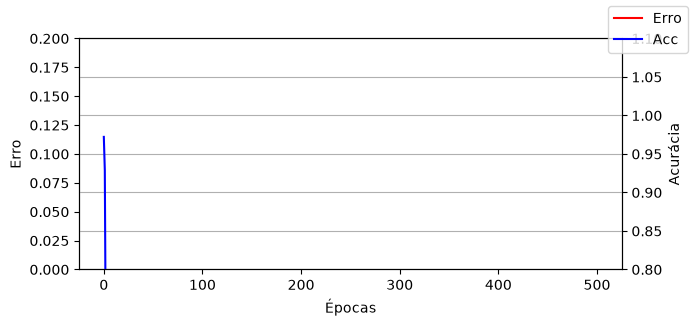

In [19]:
plot_loss(folds_loss, folds_acc)